# Ανίχνευση και Ανάλυση Θαλάσσιων Καυσώνων στον Πατραϊκό Κόλπο και το Ιόνιο με Δορυφορικά Δεδομένα SST

*Detection and Analysis of Marine Heatwaves in the Patraikos Gulf and Ionian Sea using Satellite SST Data*

**Περιοχή μελέτης:** Πατραϊκός Κόλπος (σημείο-αναφορά) & Ιόνιο ανοιχτά Κυλλήνης-Κεφαλονιάς-Αράξου (χωρική ανάλυση)
**Περίοδος:** 1982–2026 (περίοδος αναφοράς/baseline: 1982–2011)
**Δεδομένα:** Copernicus Marine Service — Mediterranean SST L4 Reprocessed (0.05°, ημερήσια)
**Μεθοδολογία:** Hobday et al. (2016, 2018), υλοποιημένη μέσω της βιβλιοθήκης [`xmhw`](https://github.com/coecms/xmhw)

## Σκοπός

Ανίχνευση επεισοδίων θαλάσσιου καύσωνα (Marine Heatwaves) σε σημείο-αναφορά στον Πατραϊκό Κόλπο,
καθώς και χωρική ανάλυση έντασης/συχνότητας καυσώνων στο Ιόνιο Πέλαγος, ανοιχτά
Κυλλήνης-Κεφαλονιάς-Αράξου. Ετήσια στατιστικά ημερών καύσωνα και δοκιμή ευαισθησίας στην περίοδο αναφοράς.


## 1. Λήψη Δεδομένων — Σημείο Αναφοράς (Πατραϊκός Κόλπος, 1982–2026)

Λήψη ημερήσιας χρονοσειράς SST για μικρή περιοχή γύρω από το σημείο μελέτης, μέσω του επίσημου
Python client του Copernicus Marine Service.


In [1]:
import warnings
warnings.filterwarnings("ignore")


import copernicusmarine
from pathlib import Path

out_dir = Path("./data")
out_dir.mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

fname = "sst_1982_2026_patra.nc"
target = out_dir / fname
target.unlink(missing_ok=True)   # σβήνει παλιό αρχείο, ώστε να μη δημιουργηθεί "(1)"

resp = copernicusmarine.subset(
    dataset_id="cmems_SST_MED_SST_L4_REP_OBSERVATIONS_010_021",
    variables=["analysed_sst"],
    minimum_longitude=21.68,
    maximum_longitude=21.78,
    minimum_latitude=38.20,
    maximum_latitude=38.30,
    start_datetime="1982-01-01T00:00:00",
    end_datetime="2026-07-23T00:00:00",
    output_filename=fname,
    output_directory=str(out_dir),
)

# Έλεγχος ότι το αρχείο που ζήτησες είναι αυτό που δημιουργήθηκε
assert target.exists(), f"Δεν βρέθηκε το {target}. Το download έδωσε: {resp.file_path}"
print("OK ->", target)

INFO - 2026-10-12T12:27:15Z - Selected dataset version: "202411"
INFO - 2026-10-12T12:27:15Z - Selected dataset part: "default"
INFO - 2026-10-12T12:27:25Z - Total size of the download: 140.53 KB.


OK -> data\sst_1982_2026_patra.nc


## 2. Ανίχνευση Θαλάσσιου Καύσωνα — Σημείο Αναφοράς

Υπολογισμός climatology baseline, κατωφλίου (90ό εκατοστημόριο) και ανίχνευση επεισοδίων με τη
μέθοδο Hobday, πάνω στη χρονοσειρά του σημείου αναφοράς.


In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from xmhw.xmhw import threshold, detect

# Άνοιγμα δεδομένων & προετοιμασία χρονοσειράς
ds = xr.open_dataset("data/sst_1982_2026_patra.nc")

sst = ds["analysed_sst"].mean(dim=["latitude", "longitude"]) - 273.15
sst.name = "sst"

# Climatology (seas) + κατώφλι (thresh)
clim = threshold(sst, climatologyPeriod=[1982, 2011])

# Ανίχνευση επεισοδίων καύσωνα
mhw = detect(sst, clim["thresh"], clim["seas"])

n_events = int(mhw["duration"].dropna(dim="events").size)
print(f"Αριθμός επεισοδίων θαλάσσιου καύσωνα που ανιχνεύθηκαν: {n_events}")

calendar not in keys
Αριθμός επεισοδίων θαλάσσιου καύσωνα που ανιχνεύθηκαν: 149


### Τα 5 πιο έντονα επεισόδια (κατά μέγιστη ένταση)

In [3]:
cat_names = {1: "Moderate", 2: "Strong", 3: "Severe", 4: "Extreme"}
if n_events > 0:
    valid = mhw.dropna(dim="events", subset=["duration"])
    top5 = valid.sortby("intensity_max", ascending=False).isel(events=slice(0, 5))

    print("Τα 5 πιο έντονα επεισόδια:")
    for i in range(top5.sizes["events"]):
        start = top5["time_start"].values[i]
        end = top5["time_end"].values[i]
        duration = top5["duration"].values[i]
        intensity = top5["intensity_max"].values[i]
        category = cat_names.get(int(top5["category"].values[i]), "?")
        print(f"  - Έναρξη: {np.datetime_as_string(start, unit='D')}, "
              f"Λήξη: {np.datetime_as_string(end, unit='D')}, "
              f"Διάρκεια: {duration:.0f} ημέρες, "
              f"Μέγιστη ένταση: {intensity:.2f} °C, "
              f"Κατηγορία: {category}")

Τα 5 πιο έντονα επεισόδια:
  - Έναρξη: 2007-06-21, Λήξη: 2007-07-05, Διάρκεια: 15 ημέρες, Μέγιστη ένταση: 4.27 °C, Κατηγορία: Strong
  - Έναρξη: 2024-03-26, Λήξη: 2024-04-30, Διάρκεια: 36 ημέρες, Μέγιστη ένταση: 4.13 °C, Κατηγορία: Extreme
  - Έναρξη: 2024-07-12, Λήξη: 2024-10-02, Διάρκεια: 83 ημέρες, Μέγιστη ένταση: 4.09 °C, Κατηγορία: Strong
  - Έναρξη: 2023-06-26, Λήξη: 2023-08-11, Διάρκεια: 47 ημέρες, Μέγιστη ένταση: 4.01 °C, Κατηγορία: Strong
  - Έναρξη: 2025-07-12, Λήξη: 2025-07-27, Διάρκεια: 16 ημέρες, Μέγιστη ένταση: 3.99 °C, Κατηγορία: Strong


### Οπτικοποίηση: SST, Climatology, Κατώφλι & Επεισόδια Καύσωνα

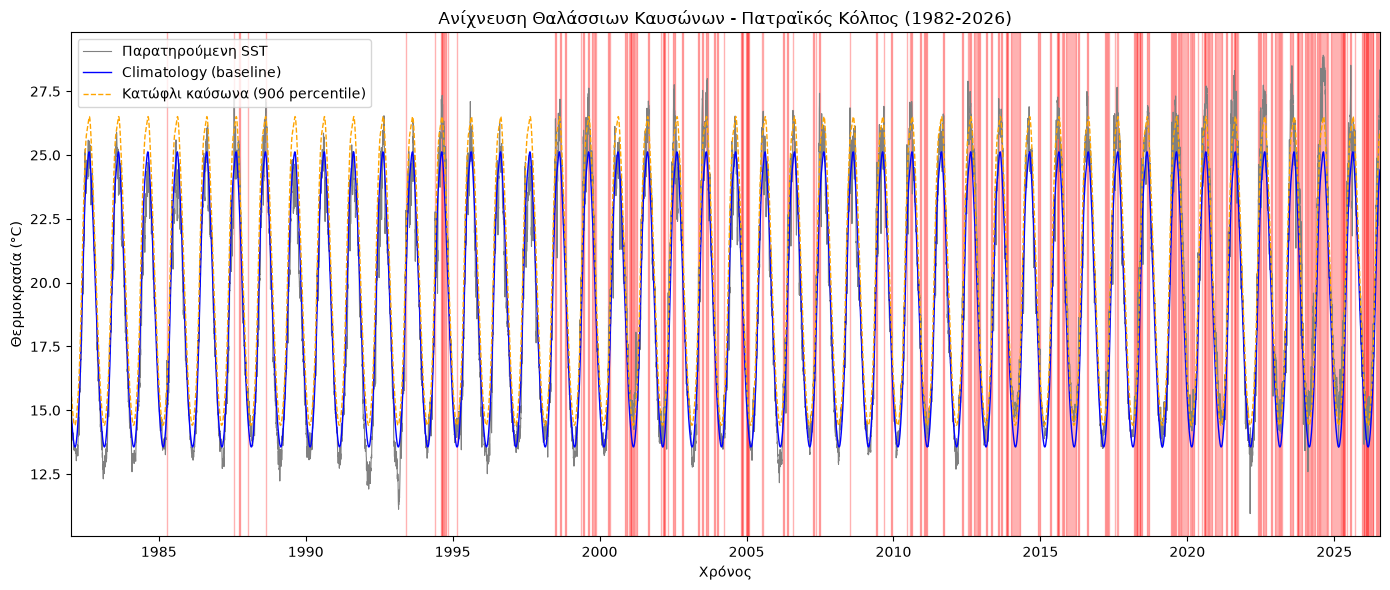

In [4]:
# "Άπλωμα" του climatology/thresh στη διάσταση χρόνου (από day-of-year σε πλήρη χρονοσειρά)
doy = sst["time"].dt.dayofyear
seas_ts = clim["seas"].sel(doy=doy)
thresh_ts = clim["thresh"].sel(doy=doy)

plt.figure(figsize=(14, 6))
sst.plot(color="gray", linewidth=0.8, label="Παρατηρούμενη SST")
seas_ts.plot(color="blue", linewidth=1, label="Climatology (baseline)")
thresh_ts.plot(color="orange", linewidth=1, linestyle="--", label="Κατώφλι καύσωνα (90ό percentile)")

if n_events > 0:
    valid = mhw.dropna(dim="events", subset=["duration"])
    for i in range(valid.sizes["events"]):
        start = valid["time_start"].values[i]
        end = valid["time_end"].values[i]
        plt.axvspan(start, end, color="red", alpha=0.3)

plt.title("Ανίχνευση Θαλάσσιων Καυσώνων - Πατραϊκός Κόλπος (1982-2026)")
plt.xlabel("Χρόνος")
plt.ylabel("Θερμοκρασία (°C)")
plt.legend()
plt.xlim(sst["time"].values[0], sst["time"].values[-1])
plt.tight_layout()
plt.savefig("figures/mhw_timeseries.png", dpi=200, bbox_inches="tight")
plt.show()

### Τα 5 μεγαλύτερης διάρκειας επεισόδια

Ταξινόμηση κατά διάρκεια (και όχι κατά ένταση), ώστε να ελεγχθεί ποια επεισόδια είναι τα μακρύτερα της περιόδου.

In [5]:
cat_names = {1: "Moderate", 2: "Strong", 3: "Severe", 4: "Extreme"}

valid = mhw.dropna(dim="events", subset=["duration"])
top_dur = valid.sortby("duration", ascending=False).isel(events=slice(0, 5))

print("Τα 5 μεγαλύτερης διάρκειας επεισόδια:")
for i in range(top_dur.sizes["events"]):
    start = np.datetime_as_string(top_dur["time_start"].values[i], unit="D")
    end = np.datetime_as_string(top_dur["time_end"].values[i], unit="D")
    cat = cat_names.get(int(top_dur["category"].values[i]), "?")
    print(f"  - {start} → {end} | {top_dur['duration'].values[i]:.0f} ημέρες | "
          f"max {top_dur['intensity_max'].values[i]:.2f} °C | {cat}")

Τα 5 μεγαλύτερης διάρκειας επεισόδια:
  - 2015-11-16 → 2016-03-20 | 126 ημέρες | max 1.84 °C | Strong
  - 2024-11-22 → 2025-03-25 | 124 ημέρες | max 2.80 °C | Strong
  - 2013-12-31 → 2014-04-18 | 109 ημέρες | max 1.75 °C | Strong
  - 2020-12-09 → 2021-03-13 | 95 ημέρες | max 2.37 °C | Strong
  - 2019-10-13 → 2020-01-04 | 84 ημέρες | max 2.53 °C | Strong


### Ημέρες Καύσωνα ανά Έτος (baseline 1982–2011)

Αριθμός ημερών κάθε έτους που ανήκουν σε επεισόδιο καύσωνα. Το 2026 εξαιρείται, γιατί είναι ημιτελές (έως 23 Ιουλίου).

year
2024    246
2025    168
2023    166
2020    148
2014    135
2021    132
2019    130
2018    112
Name: sst, dtype: int64


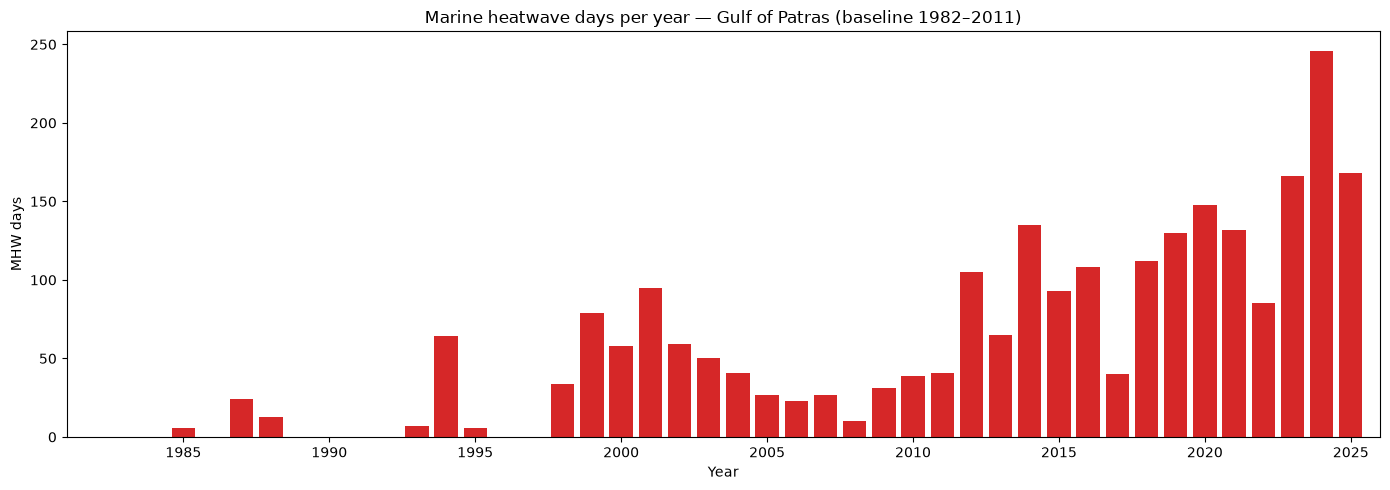

In [6]:
# Ημερήσια μάσκα: True τις ημέρες που ανήκουν σε επεισόδιο
valid = mhw.dropna(dim="events", subset=["duration"])
mhw_day = xr.zeros_like(sst, dtype=bool)
for s, e in zip(valid["time_start"].values, valid["time_end"].values):
    mhw_day.loc[dict(time=slice(s, e))] = True

days_per_year = mhw_day.groupby("time.year").sum()
days_full = days_per_year.sel(year=slice(None, 2025))   # χωρίς το ημιτελές 2026

print(days_full.to_series().sort_values(ascending=False).head(8))

plt.figure(figsize=(14, 5))
plt.bar(days_full["year"].values, days_full.values, color="tab:red")
plt.title("Marine heatwave days per year — Gulf of Patras (baseline 1982–2011)")
plt.xlabel("Year")
plt.ylabel("MHW days")
plt.xlim(1981, 2026)
plt.tight_layout()
plt.savefig("figures/mhw_days_per_year.png", dpi=200, bbox_inches="tight")
plt.show()

### Δοκιμή Ευαισθησίας: Περίοδος Αναφοράς (1982–2011 έναντι 1982–2025)

Επανάληψη της ανίχνευσης με baseline 1982–2025, για να φανεί πόσο εξαρτώνται τα αποτελέσματα από την επιλογή περιόδου αναφοράς.

calendar not in keys
Επεισόδια — baseline 1982-2011: 149
Επεισόδια — baseline 1982-2025: 77


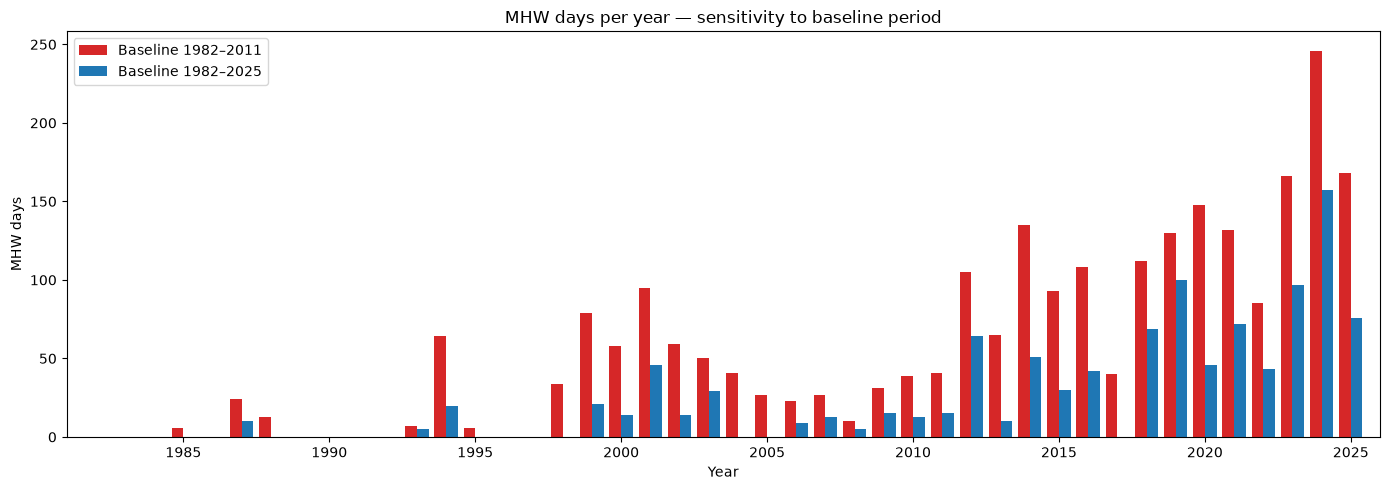

Σύνολο ημερών καύσωνα, baseline 1982–2025 / baseline 1982–2011: 0.44
Ημέρες καύσωνα το 2024 με baseline 1982–2025: 157


In [7]:
clim_b2 = threshold(sst, climatologyPeriod=[1982, 2025])
mhw_b2 = detect(sst, clim_b2["thresh"], clim_b2["seas"])

valid_b2 = mhw_b2.dropna(dim="events", subset=["duration"])
mhw_day_b2 = xr.zeros_like(sst, dtype=bool)
for s, e in zip(valid_b2["time_start"].values, valid_b2["time_end"].values):
    mhw_day_b2.loc[dict(time=slice(s, e))] = True

days_b2 = mhw_day_b2.groupby("time.year").sum().sel(year=slice(None, 2025))

print("Επεισόδια — baseline 1982-2011:", valid.sizes["events"])
print("Επεισόδια — baseline 1982-2025:", valid_b2.sizes["events"])

plt.figure(figsize=(14, 5))
plt.bar(days_full["year"].values - 0.2, days_full.values, width=0.4,
        label="Baseline 1982–2011", color="tab:red")
plt.bar(days_b2["year"].values + 0.2, days_b2.values, width=0.4,
        label="Baseline 1982–2025", color="tab:blue")
plt.title("MHW days per year — sensitivity to baseline period")
plt.xlabel("Year")
plt.ylabel("MHW days")
plt.legend()
plt.xlim(1981, 2026)
plt.tight_layout()
plt.savefig("figures/mhw_baseline_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()

ratio = days_b2.sum().item() / days_full.sum().item()
print(f"Σύνολο ημερών καύσωνα, baseline 1982–2025 / baseline 1982–2011: {ratio:.2f}")
print(f"Ημέρες καύσωνα το 2024 με baseline 1982–2025: {days_b2.sel(year=2024).item()}")

## 3. Λήψη Δεδομένων — Ευρύτερη Περιοχή (Χωρική Ανάλυση)

Λήψη δεδομένων SST για μικρή περιοχή στο Ιόνιο Πέλαγος, ανοιχτά Κυλλήνης-Κεφαλονιάς-Αράξου (δυτικά της εισόδου του Πατραϊκού Κόλπου), ώστε να αναλυθούν
χωρικά μοτίβα έντασης και συχνότητας καυσώνων.


In [8]:
import copernicusmarine
from pathlib import Path

out_dir = Path("./data")
out_dir.mkdir(exist_ok=True)

fname = "sst_region_1982_2026.nc"
target = out_dir / fname
target.unlink(missing_ok=True)

resp = copernicusmarine.subset(
    dataset_id="cmems_SST_MED_SST_L4_REP_OBSERVATIONS_010_021",
    variables=["analysed_sst"],
    minimum_longitude=20.77,
    maximum_longitude=21.45,
    minimum_latitude=37.90,
    maximum_latitude=38.30,
    start_datetime="1982-01-01T00:00:00",
    end_datetime="2026-07-23T00:00:00",
    output_filename=fname,
    output_directory=str(out_dir),
)

assert target.exists(), f"Δεν βρέθηκε το {target}. Το download έδωσε: {resp.file_path}"
print("OK ->", target)

INFO - 2026-10-12T12:27:58Z - Selected dataset version: "202411"
INFO - 2026-10-12T12:27:58Z - Selected dataset part: "default"
INFO - 2026-10-12T12:28:17Z - Total size of the download: 2.84 MB.


OK -> data\sst_region_1982_2026.nc


## 4. Χωρική Ανάλυση: Ανίχνευση Καύσωνα σε Κάθε Σημείο Πλέγματος

Εφαρμογή της ίδιας μεθοδολογίας ανίχνευσης σε κάθε σημείο του χωρικού πλέγματος στο Ιόνιο
(ανοιχτά Κυλλήνης-Κεφαλονιάς-Αράξου) — 91 σημεία, grid 7×13 — ώστε να εντοπιστούν περιοχές με
υψηλότερη ένταση/συχνότητα καυσώνων.


In [9]:
ds_region = xr.open_dataset("data/sst_region_1982_2026.nc")
sst_region = ds_region["analysed_sst"] - 273.15
sst_region.name = "sst"
print(sst_region.shape)  # (χρόνος, latitude, longitude)

clim_region = threshold(sst_region, climatologyPeriod=[1982, 2011])
mhw_region = detect(sst_region, clim_region["thresh"], clim_region["seas"])

(16275, 7, 13)
calendar not in keys


### Χάρτης: Μέγιστη Ένταση Καύσωνα ανά Σημείο

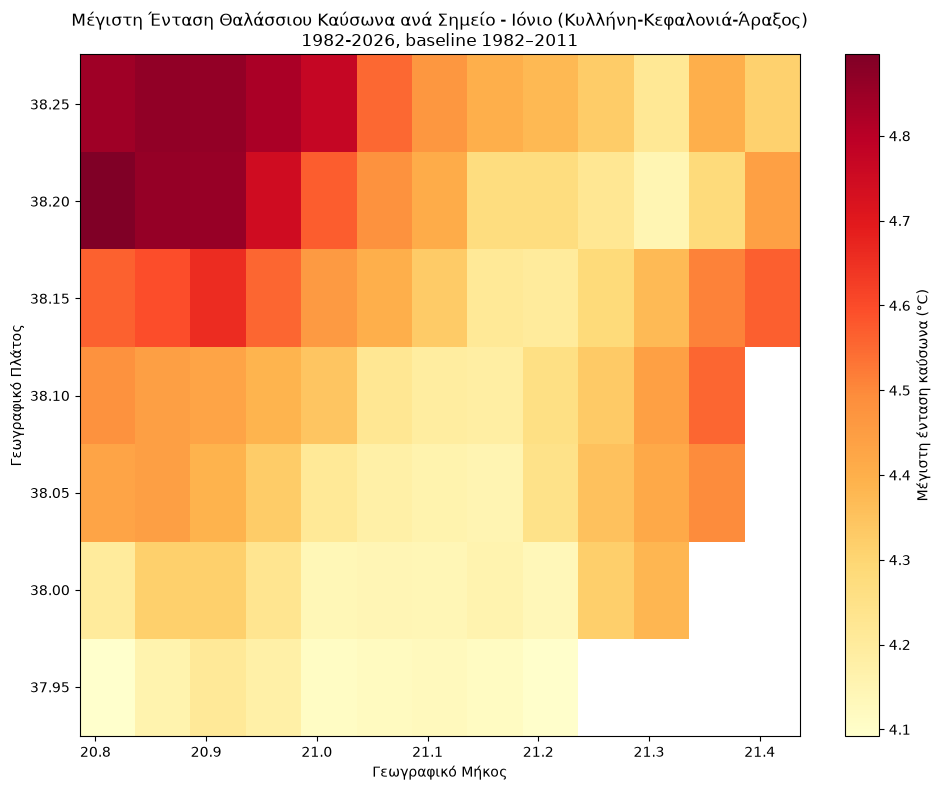

In [10]:
sea_mask = sst_region.notnull().any("time")
max_intensity_map = mhw_region["intensity_max"].max(dim="events", skipna=True).where(sea_mask)

plt.figure(figsize=(10, 8))
max_intensity_map.plot(cmap="YlOrRd", cbar_kwargs={"label": "Μέγιστη ένταση καύσωνα (°C)"})
plt.title("Μέγιστη Ένταση Θαλάσσιου Καύσωνα ανά Σημείο - Ιόνιο (Κυλλήνη-Κεφαλονιά-Άραξος)\n1982-2026, baseline 1982–2011")
plt.xlabel("Γεωγραφικό Μήκος")
plt.ylabel("Γεωγραφικό Πλάτος")
plt.tight_layout()
plt.show()

### Χάρτης: Συνολικός Αριθμός Επεισοδίων ανά Σημείο

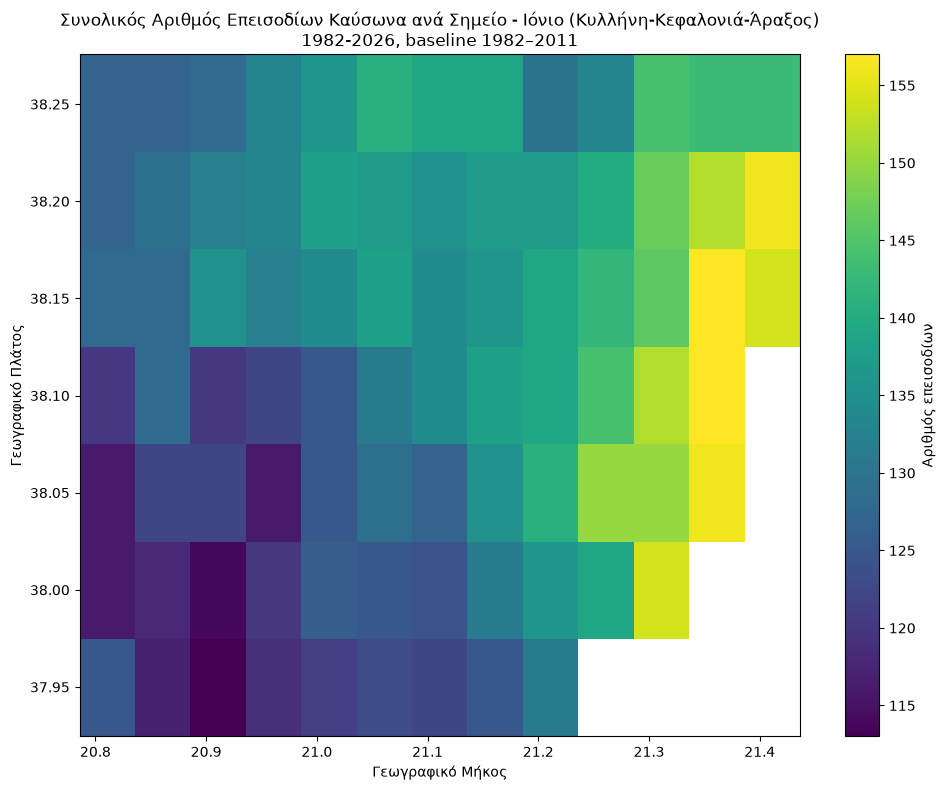

In [11]:
sea_mask = sst_region.notnull().any("time")
n_events_map = mhw_region["duration"].count(dim="events").where(sea_mask)

plt.figure(figsize=(10, 8))
n_events_map.plot(cmap="viridis", cbar_kwargs={"label": "Αριθμός επεισοδίων"})
plt.title("Συνολικός Αριθμός Επεισοδίων Καύσωνα ανά Σημείο - Ιόνιο (Κυλλήνη-Κεφαλονιά-Άραξος)\n1982-2026, baseline 1982–2011")
plt.xlabel("Γεωγραφικό Μήκος")
plt.ylabel("Γεωγραφικό Πλάτος")
plt.tight_layout()
plt.show()

### Χάρτης: Ημέρες Καύσωνα ανά Έτος (ανά Σημείο)
Μέσος αριθμός ημερών ανά έτος σε επεισόδιο καύσωνα, για την περίοδο αναφοράς (1982–2011)
και για τα τελευταία 10 πλήρη έτη (2016–2025).

Μέσος όρος ημερών/έτος, 1982–2011: 23.6
Μέσος όρος ημερών/έτος, 2016–2025: 154.0
Εύρος 2016–2025 ανά pixel: 146 – 167


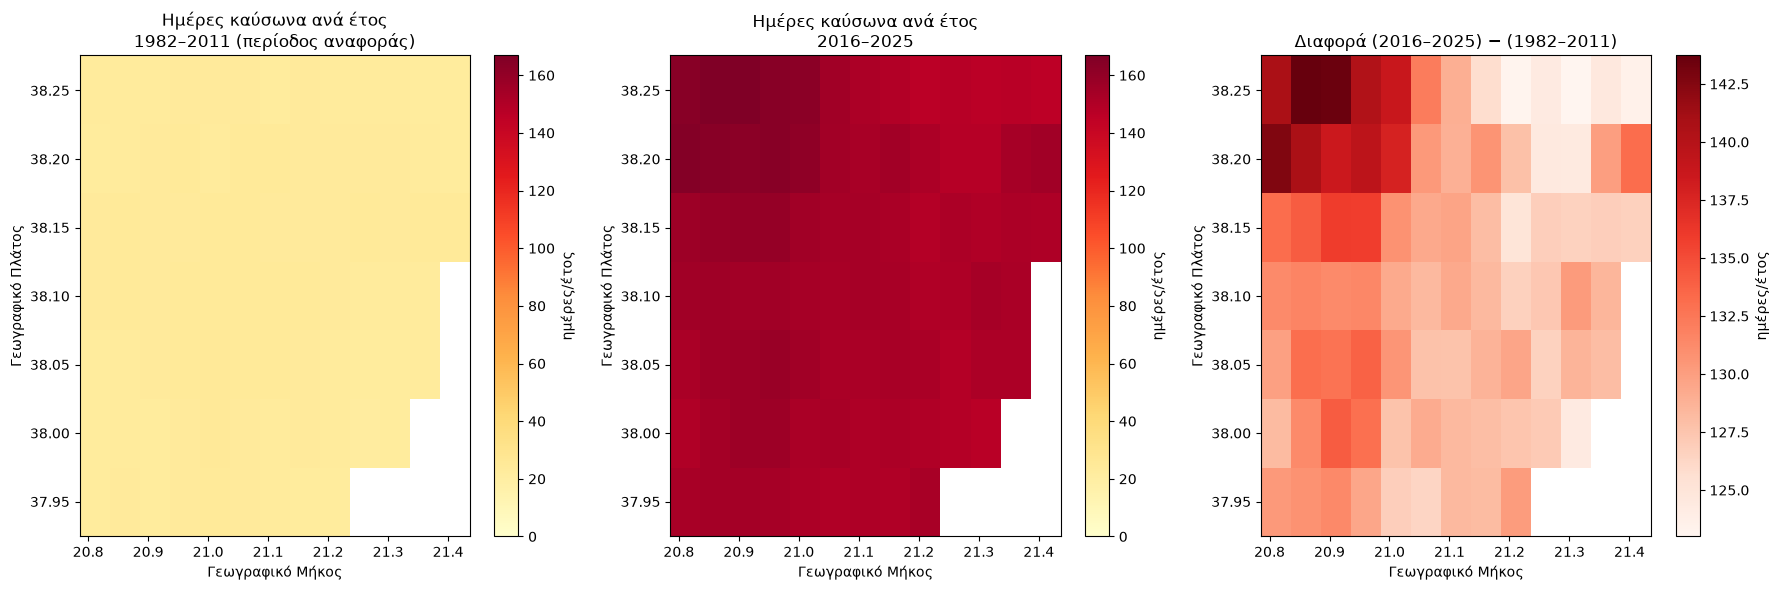

In [12]:
lats = sst_region["latitude"].values
lons = sst_region["longitude"].values
times = sst_region["time"].values
years = sst_region["time"].dt.year.values

# Ημερήσια μάσκα καύσωνα για κάθε pixel: (χρόνος, lat, lon)
mhw_days = np.zeros((len(times), len(lats), len(lons)), dtype=bool)
for i in range(len(lats)):
    for j in range(len(lons)):
        ts = mhw_region["time_start"].isel(latitude=i, longitude=j).values
        te = mhw_region["time_end"].isel(latitude=i, longitude=j).values
        ok = ~np.isnat(ts) & ~np.isnat(te)
        for s, e in zip(ts[ok], te[ok]):
            mhw_days[(times >= s) & (times <= e), i, j] = True

sea_mask = sst_region.notnull().any("time")   # False = ξηρά

def mean_days_per_year(y0, y1):
    sel = (years >= y0) & (years <= y1)
    d = mhw_days[sel].sum(axis=0) / (y1 - y0 + 1)
    return xr.DataArray(d, coords={"latitude": lats, "longitude": lons},
                        dims=["latitude", "longitude"]).where(sea_mask)

base = mean_days_per_year(1982, 2011)
recent = mean_days_per_year(2016, 2025)
diff = recent - base

print(f"Μέσος όρος ημερών/έτος, 1982–2011: {float(base.mean()):.1f}")
print(f"Μέσος όρος ημερών/έτος, 2016–2025: {float(recent.mean()):.1f}")
print(f"Εύρος 2016–2025 ανά pixel: {float(recent.min()):.0f} – {float(recent.max()):.0f}")

vmax = float(recent.max())
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
base.plot(ax=axes[0], cmap="YlOrRd", vmin=0, vmax=vmax,
          cbar_kwargs={"label": "ημέρες/έτος"})
axes[0].set_title("Ημέρες καύσωνα ανά έτος\n1982–2011 (περίοδος αναφοράς)")
recent.plot(ax=axes[1], cmap="YlOrRd", vmin=0, vmax=vmax,
            cbar_kwargs={"label": "ημέρες/έτος"})
axes[1].set_title("Ημέρες καύσωνα ανά έτος\n2016–2025")
diff.plot(ax=axes[2], cmap="Reds", cbar_kwargs={"label": "ημέρες/έτος"})
axes[2].set_title("Διαφορά (2016–2025) − (1982–2011)")
for ax in axes:
    ax.set_xlabel("Γεωγραφικό Μήκος")
    ax.set_ylabel("Γεωγραφικό Πλάτος")
plt.tight_layout()
plt.savefig("figures/mhw_days_per_pixel.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Έλεγχος Ποιότητας Δεδομένων

Οι λευκές περιοχές (χωρίς τιμή) στους χάρτες της ενότητας 4 αντιστοιχούν σε σημεία πάνω σε **ξηρά**
(ακτογραμμή εντός του bounding box), όχι σε σφάλμα ανάλυσης. Επιβεβαιώνεται παρακάτω μέσω ελέγχου
ελλειπών τιμών (NaN), και επαληθεύτηκε οπτικά μέσω Google Earth.

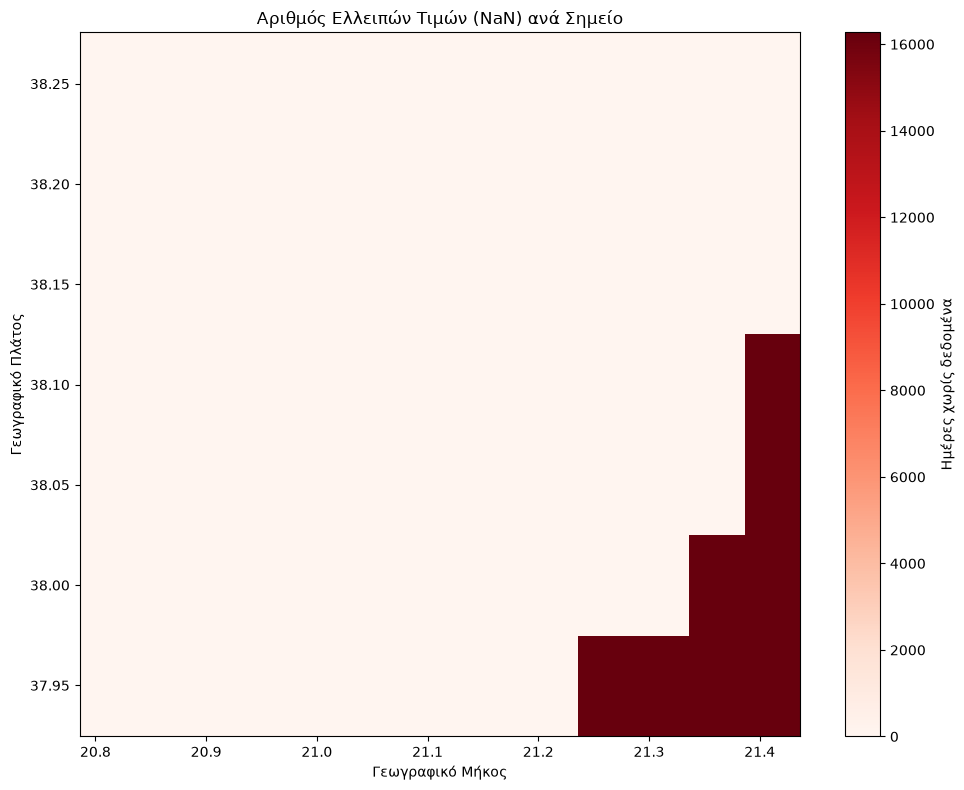

In [13]:
nan_count = sst_region.isnull().sum(dim="time")

plt.figure(figsize=(10, 8))
nan_count.plot(cmap="Reds",cbar_kwargs={"label": "Ημέρες χωρίς δεδομένα"})
plt.title("Αριθμός Ελλειπών Τιμών (NaN) ανά Σημείο")
plt.xlabel("Γεωγραφικό Μήκος")
plt.ylabel("Γεωγραφικό Πλάτος")
plt.tight_layout()
plt.show()

## 6. Συμπεράσματα

Περίοδος 1982–23 Ιουλίου 2026, περίοδος αναφοράς (baseline) 1982–2011, μέθοδος Hobday (κατώφλι 90ού εκατοστημορίου).

### Πατραϊκός Κόλπος (σημείο αναφοράς)

- Ανιχνεύθηκαν **149 επεισόδια** θαλάσσιου καύσωνα.
- Οι ημέρες καύσωνα ανά έτος αυξάνονται σαφώς: χαμηλές έως το 2011 και πάνω από 100 τα περισσότερα έτη μετά το 2018.
- Το **2024 είναι το έτος-ρεκόρ με 246 ημέρες**, έναντι 168 το 2025 και 166 το 2023.
- Το πιο έντονο επεισόδιο (μέγιστη ένταση) είναι του **Ιουνίου 2007** (4.27 °C, 15 ημέρες). Το 2024 έχει δύο από τα τρία πιο έντονα: Μάρτιος–Απρίλιος (36 ημέρες, 4.13 °C, κατηγορία Extreme) και Ιούλιος–Οκτώβριος (83 ημέρες, 4.09 °C).
- Τα μεγαλύτερης διάρκειας επεισόδια είναι χειμερινά (126 ημέρες Νοέμ. 2015–Μάρτ. 2016, 124 ημέρες Νοέμ. 2024–Μάρτ. 2025) με χαμηλότερη ένταση (1.8–2.8 °C). Πιθανότατα αντανακλούν τη γενική μετατόπιση της θερμοκρασίας προς υψηλότερες τιμές και όχι ξεχωριστούς καύσωνες.
- **Ευαισθησία στη baseline:** με baseline 1982–2025 τα επεισόδια πέφτουν από 149 σε 77 και οι ημέρες ανά έτος κατά περίπου 56%. Το μοτίβο μένει ίδιο (ανοδική τάση, το 2024 πρώτο), άρα τα ποιοτικά συμπεράσματα είναι ανθεκτικά, τα ποσοτικά όχι.

### Ιόνιο (Κυλλήνη–Κεφαλονιά–Άραξος)

- Ο μέσος αριθμός ημερών καύσωνα ανά έτος στην περιοχή αυξήθηκε από **23.6 (1982–2011) σε 154 (2016–2025)**.
- Η χωρική διαφοροποίηση είναι μικρή (146–167 ημέρες ανά pixel το 2016–2025), άρα το σήμα είναι ευρείας κλίμακας.
- Η μεγαλύτερη αύξηση και η μεγαλύτερη μέγιστη ένταση εντοπίζονται στα βορειοδυτικά της περιοχής (ανοιχτά), και η μικρότερη αύξηση στα ανατολικά, κοντά στην ακτή. Η αιτία δεν έχει εξεταστεί.

### Περιορισμοί

- Ένα μόνο προϊόν (L4 REP, 0.05°, παρεμβαλλόμενο). Δεν έχει γίνει επικύρωση με in-situ δεδομένα ή άλλο προϊόν, ούτε έλεγχος ομοιογένειας για τα 44 χρόνια. Τα παράκτια pixel είναι πιο αβέβαια.
- Τα αποτελέσματα εξαρτώνται σημαντικά από την επιλογή baseline, ιδίως επειδή η θάλασσα θερμαίνεται.
- Το "σημείο αναφοράς" είναι ο μέσος όρος περίπου 4 pixels (2×2) κοντά στην ακτή.
- Η μέγιστη ένταση ανά pixel καθορίζεται από ένα μόνο επεισόδιο και ο αριθμός επεισοδίων εξαρτάται από το πώς χωρίζονται ή ενώνονται. Οι ημέρες ανά έτος είναι πιο αξιόπιστος δείκτης.
- Το 2026 είναι ημιτελές και δεν περιλαμβάνεται στα ετήσια στατιστικά.
- Η ανάλυση είναι περιγραφική: δεν έγινε έλεγχος στατιστικής σημαντικότητας της τάσης.
- Το bounding box της χωρικής ανάλυσης περιλαμβάνει τμήματα ξηράς (χωρίς δεδομένα).

### Βιβλιογραφία

- Hobday, A.J. et al. (2016). *A hierarchical approach to defining marine heatwaves.* Progress in Oceanography.
- Hobday, A.J. et al. (2018). *Categorizing and naming marine heatwaves.* Oceanography, 31(2), 162-173.
- Pastor, F., Paredes-Fortuny, L. & Khodayar, S. (2024). *Mediterranean marine heatwaves intensify in
  the presence of concurrent atmospheric heatwaves.* Communications Earth & Environment.
